# 03. Modelli classici, bigrammi e ottimizzazione

**Progetto:** HelpDesk AI · **Passo 2:** modelli

In questo notebook cerchiamo di migliorare l'F1 macro di 0,8453 ottenuto nel notebook 02 in tre modi:
1. **Altri algoritmi:** Naive Bayes, k-NN e SVM lineare, oltre alla regressione logistica.
2. **Bigrammi:** coppie di parole consecutive, per risolvere errori come *time card* (presenze) confuso con *card* (badge d'accesso).
3. **Ottimizzazione dei parametri** del modello migliore.

Per confrontare tante varianti in modo affidabile introduciamo la **cross-validation per gruppi**.

## Cosa faremo:

1. Import e configurazione
2. Caricamento della divisione salvata nel notebook 02
3. La cross-validation per gruppi
4. Confronto tra algoritmi
5. Bigrammi
6. Ottimizzazione dei parametri
7. Verifica sulla validation
8. Probabilità per l'app
9. Salvataggio
10. Riepilogo

# 1. Import e configurazione
Le novità rispetto al notebook 02:

| Strumento | A cosa serve |
|---|---|
| `cross_val_score` | stimare le prestazioni di un modello con la cross-validation |
| `GridSearchCV` | provare automaticamente tutte le combinazioni di parametri, con la cross-validation |
| `ComplementNB` | Naive Bayes, versione adatta a testi con categorie sbilanciate |
| `KNeighborsClassifier` | k-NN: classifica guardando i ticket più simili |
| `LinearSVC` | SVM con confine di decisione lineare |
| `CalibratedClassifierCV` | ottenere probabilità da modelli che non le forniscono |
| `time` | misurare quanto impiega ogni esperimento |

In [1]:
from pathlib import Path
import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.base import clone
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import StratifiedGroupKFold, cross_val_score, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import ComplementNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

In [2]:
# --- Riproducibilità ---
RANDOM_STATE = 42

# --- Percorsi ---
PROJECT_DIR = Path("..")
SPLIT_PATH = PROJECT_DIR / "data" / "processed" / "tickets_split.csv"
MODELS_DIR = PROJECT_DIR / "models"

# --- Colonne ---
TEXT_COL = "Document"
LABEL_COL = "Topic_group"

# Per la cross-validation usiamo tutti i core del processore. Se il PC rallenta troppo si può variare N_JOBS = 1 (più lento ma più leggero)
N_JOBS = -1

# --- Stile dei grafici ---
COLORE = "#2a78d6"
TESTO_SECONDARIO = "#52514e"
GRIGLIA = "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": GRIGLIA,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": GRIGLIA,
    "xtick.color": TESTO_SECONDARIO,
    "ytick.color": TESTO_SECONDARIO,
})
pd.set_option("display.max_colwidth", 200)

# 2. Caricamento della divisione
Carichiamo il file salvato nel notebook 02 così usiamo esattamente fli stessi insiemi di train e validation per permetterci risultati confrontabili. Carichiamo anche la lista del rumore email.

In [3]:
df = pd.read_csv(SPLIT_PATH)
train = df[df["split"] == "train"]
val = df[df["split"] == "val"]

X_train, y_train = train[TEXT_COL], train[LABEL_COL]
gruppi_train = train["gruppo"]      # servono alla cross-validation per gruppi
X_val, y_val = val[TEXT_COL], val[LABEL_COL]

with open(MODELS_DIR / "liste_parole.json", encoding="utf-8") as f:
    RUMORE_EMAIL = json.load(f)["rumore_email"]

print(f"Train: {len(train)} ticket | Validation: {len(val)} ticket")
print(f"Parole nella lista 'rumore email': {len(RUMORE_EMAIL)}")

Train: 38359 ticket | Validation: 4739 ticket
Parole nella lista 'rumore email': 39


# 3. La cross-validation per gruppi
**Come funziona:**
Dividiamo il train in 5 parti ed addestriamo il modello 5 volte: ogni volta su 4 parti misurandolo sulla quinta. Otteniamo così 5 punteggi. Calcolando la media avremo una stima più stabile di un singolo punteggio, mentre, la deviazione standard ci dice quando il risultato varia da una parte all'altra: se i due modelli differiscono meno di una deviazione standard non possiamo dire che uno sia migliore dell'altro.

In [4]:
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def crea_pipeline(classificatore, ngram_range=(1,1)):
    # TF-IDF (senza rumore email come scelto nel notebook 2) + classificatore scelto
    return Pipeline([
        ("tfidf", TfidfVectorizer(min_df=5, stop_words=RUMORE_EMAIL, ngram_range=ngram_range)),
        ("classificatore", classificatore),
    ])

def valuta_cv(modello, nome):
    # Cross-Validation per gruppi sul train: restituisce media, deviazione standard e tempo
    inizio = time.perf_counter()
    punteggi = cross_val_score(modello, X_train, y_train, groups=gruppi_train, cv=cv, scoring="f1_macro", n_jobs=N_JOBS)
    return{
        "configurazione": nome,
        "F1 macro (media)": round(float(punteggi.mean()), 4),
        "deviazione standard": round(float(punteggi.std()), 4),
        "tempo (s)": round(time.perf_counter() - inizio, 1),
    }

### Controllo baseline in cross-validation
Controlliamo il baseline del notebook 02 con la cross-validation, se il valore fosse molto diverso da 0,8453 ci sarebbe qualcosa da capire prima di proseguire

In [5]:
%%time
baseline_cv = valuta_cv(crea_pipeline(LogisticRegression(class_weight="balanced", max_iter=1000)),
                        "Baseline: regressione logistica | parole singole")
display(pd.DataFrame([baseline_cv]).set_index("configurazione"))

,F1 macro (media),deviazione standard,tempo (s)
configurazione,,,
Baseline: regressione logistica | parole singole,0.8447,0.0075,8.8


CPU times: total: 4.25 s
Wall time: 8.8 s


### Osservazioni (parte 3)

- Baseline in cross-validation per gruppi: **F1 macro 0,8447 ± 0,0075**.
- Coincide con il risultato sulla validation del notebook 02 (0,8453): divisione e pipeline sono coerenti.
- La deviazione standard (**0,0075**) è la soglia di affidabilità: differenze più piccole tra modelli non sono significative.

# 4. Confronto tra algoritmi 
Proviamo quattro algoritmi, tutti con le stesse parole (parole singole, senza rumore email) e con le impostazioni predefinite.

|Algoritmo | Idea | Punti di forza | Punti deboli |
|---|---|---|---|
| **Naive Bayes** (`ComplementNB`) | calcola la probabilità di ogni categoria dalle parole, supponendole indipendenti tra loro | veloce, classico per il testo | l'ipotesi di indipendenza è irrealistica |
| **k-NN** | assegna la categoria più comune tra i 10 ticket più simili | intuitivo, nessun addestramento | lento in previsione, soffre con migliaia di dimensioni |
| **Regressione logistica** | un peso per ogni parola e categoria (il nostro baseline) | robusta, dà probabilità, interpretabile | — |
| **SVM lineare** (`LinearSVC`) | cerca il confine tra categorie con il **margine più ampio** | spesso il migliore sul testo | non dà probabilità |

In [6]:
%%time
algoritmi = {
    "Naive Bayes": ComplementNB(),
    "k-NN (k=10)": KNeighborsClassifier(n_neighbors=10, metric="cosine", weights="distance", algorithm="brute"),
    "Regressione logistica": LogisticRegression(class_weight="balanced", max_iter=1000),
    "SVM lineare": LinearSVC(class_weight="balanced", random_state=RANDOM_STATE),
}

risultati = []
for nome, classificatore in algoritmi.items():
    risultati.append(valuta_cv(crea_pipeline(classificatore), f"{nome} | parole singole"))
    print("fatto:", nome)

display(pd.DataFrame(risultati).set_index("configurazione"))

fatto: Naive Bayes
fatto: k-NN (k=10)
fatto: Regressione logistica
fatto: SVM lineare


,F1 macro (media),deviazione standard,tempo (s)
configurazione,,,
Naive Bayes | parole singole,0.7745,0.0090,6.2
k-NN (k=10) | parole singole,0.7472,0.0088,22.2
Regressione logistica | parole singole,0.8447,0.0075,8.4
SVM lineare | parole singole,0.8445,0.0036,6.4


CPU times: total: 15.3 s
Wall time: 43.3 s


### Osservazioni (parte 4)

| Algoritmo | F1 macro (media ± dev. std) | Tempo |
|---|---|---|
| Regressione logistica | 0,8447 ± 0,0075 | 8,4 s |
| SVM lineare | 0,8445 ± 0,0036 | 6,4 s |
| Naive Bayes | 0,7745 ± 0,0090 | 6,2 s |
| k-NN (k=10) | 0,7472 ± 0,0088 | 22,2 s |

- **Regressione logistica e SVM lineare sono equivalenti** (differenza 0,0002, molto sotto la deviazione standard).
  La SVM è più stabile (dev. std dimezzata) e un po' più veloce.
- **Naive Bayes è 7 punti sotto**: l'ipotesi di indipendenza tra le parole è irrealistica e, con molti dati
  (38.000 ticket), i modelli discriminativi superano quelli generativi.
- **k-NN è il peggiore e il più lento**: non impara quali parole contano, soffre l'alta dimensionalità
  (migliaia di parole, ticket brevi) ed è penalizzato dallo split per gruppi, perché non trova più i "gemelli" nel train.
  È anche lento in previsione: inadatto a un'app in tempo reale.

# 5. Bigrammi
Fino ad ora ogni ticket era una gruppo di parole singole in cui l'ordine non contava. Nel notebook 02 abbiamo visto che questa cosa genera errori come:
- *time card* (foglio presenze, HR) letto come *card*(badge, Access);
- *installing memories* (RAM, Hardware) letto come *install* (software, Administrative rights).

Con `ngram_range=(1, 2)` il TF-IDF usa sia le parole singole che le coppie di parole consecutive (bigrammi). Il prezzo da pagare è che il vocabolario cresce molto per via delle tante coppie plausibili.

In [7]:
%%time
for nome in ["Naive Bayes", "Regressione logistica", "SVM lineare"]:
    classificatore = clone(algoritmi[nome])  # nuova copia non addestrata
    risultati.append(valuta_cv(crea_pipeline(classificatore, ngram_range=(1, 2)), f"{nome} | con bigrammi"))
    print("fatto:", nome)

tabella_cv = pd.DataFrame(risultati).set_index("configurazione").sort_values("F1 macro (media)", ascending=False)
display(tabella_cv)

fatto: Naive Bayes
fatto: Regressione logistica
fatto: SVM lineare


,F1 macro (media),deviazione standard,tempo (s)
configurazione,,,
SVM lineare | con bigrammi,0.8521,0.0062,8.4
Regressione logistica | con bigrammi,0.8496,0.0075,13.2
Regressione logistica | parole singole,0.8447,0.0075,8.4
SVM lineare | parole singole,0.8445,0.0036,6.4
Naive Bayes | con bigrammi,0.7996,0.0072,6.3
Naive Bayes | parole singole,0.7745,0.0090,6.2
k-NN (k=10) | parole singole,0.7472,0.0088,22.2


CPU times: total: 11.8 s
Wall time: 28 s


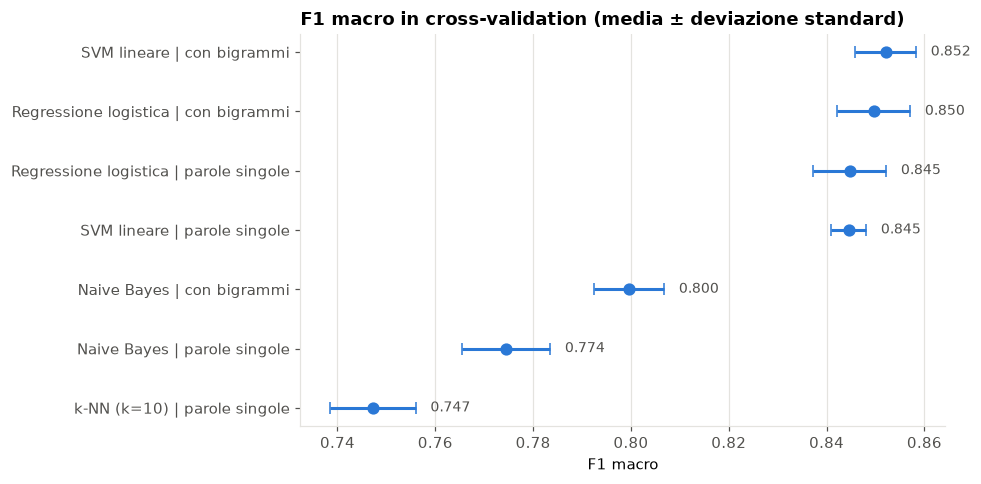

In [8]:
# Grafico: media e deviazione standard per ogni configurazione.
ordinata = tabella_cv.sort_values("F1 macro (media)")

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.errorbar(ordinata["F1 macro (media)"], ordinata.index, xerr=ordinata["deviazione standard"],
            fmt="o", color=COLORE, ecolor=COLORE, elinewidth=2, capsize=4, markersize=7)
for posizione, (nome, riga) in enumerate(ordinata.iterrows()):
    ax.text(riga["F1 macro (media)"] + riga["deviazione standard"] + 0.003, posizione,
            f"{riga['F1 macro (media)']:.3f}", va="center", fontsize=9, color=TESTO_SECONDARIO)
ax.set_title("F1 macro in cross-validation (media ± deviazione standard)")
ax.set_xlabel("F1 macro")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

## Osservazioni (parte 5)

| Configurazione | F1 macro (media ± dev. std) | Effetto dei bigrammi |
|---|---|---|
| SVM lineare con bigrammi | **0,8521 ± 0,0062** | +0,0076 |
| Regressione logistica con bigrammi | 0,8496 ± 0,0075 | +0,0049 |
| Naive Bayes con bigrammi | 0,7996 ± 0,0072 | +0,0251 |

- **I bigrammi migliorano tutti i modelli**, come ipotizzato dall'analisi degli errori (*time card*, *installing memories*).
- La **SVM lineare con bigrammi** è la migliore: il guadagno rispetto alle parole singole supera la deviazione standard.
- Regressione logistica e SVM con bigrammi restano **equivalenti** (differenza 0,0025); la SVM però è più veloce e più stabile.
- Naive Bayes guadagna di più perché i bigrammi compensano in parte la sua ipotesi di indipendenza tra le parole,
  ma resta 5 punti sotto.
- **Scelta per l'ottimizzazione: SVM lineare con bigrammi** (con calibrazione per ottenere le probabilità).

# 6. Ottimizzazione dei parametri
Ora prendiamo la configurazione migliore: **SVM lineare con bigrammi** e ne cerchiamo i parametri migliori con `GridSearchCV`

In [9]:
CONFIGURAZIONE_SCELTA = "SVM lineare | con bigrammi"

griglia = {
    "classificatore__C": [0.03, 0.1, 0.3, 1, 3],
    "classificatore__class_weight": [None, "balanced"],
    "tfidf__sublinear_tf": [False, True],
}

n_combinazioni = int(np.prod([len(valori) for valori in griglia.values()]))
print(f"Combinazioni da provare: {n_combinazioni} x {cv.get_n_splits()} fold = {n_combinazioni * cv.get_n_splits()} addestramenti")

Combinazioni da provare: 20 x 5 fold = 100 addestramenti


In [10]:
%%time
ricerca = GridSearchCV(
    crea_pipeline(LinearSVC(random_state=RANDOM_STATE), ngram_range=(1, 2)),
    param_grid=griglia,
    cv=cv,
    scoring="f1_macro",
    n_jobs=N_JOBS,
    refit=True,     # riaddestra la combinazione migliore su tutto il train
)
ricerca.fit(X_train, y_train, groups=gruppi_train)

print("Parametri migliori:", ricerca.best_params_)
print(f"F1 macro in cross-validation: {ricerca.best_score_:.4f}")

Parametri migliori: {'classificatore__C': 0.3, 'classificatore__class_weight': 'balanced', 'tfidf__sublinear_tf': True}
F1 macro in cross-validation: 0.8566
CPU times: total: 11.5 s
Wall time: 58.6 s


In [11]:
# Le 10 combinazioni migliori
colonne = [c for c in ricerca.cv_results_ if c.startswith("param_")] + ["mean_test_score", "std_test_score"]
tabella_griglia = (pd.DataFrame(ricerca.cv_results_)[colonne]
                   .sort_values("mean_test_score", ascending=False)
                   .rename(columns={"mean_test_score": "F1 macro (media)", "std_test_score": "deviazione standard"}))
tabella_griglia.columns = [c.replace("param_", "").replace("classificatore__", "").replace("tfidf__", "")
                           for c in tabella_griglia.columns]
display(tabella_griglia.head(10).round(4))

,C,class_weight,sublinear_tf,F1 macro (media),deviazione standard
11,0.3,balanced,True,0.8566,0.0043
8,0.3,NaN,False,0.8564,0.0059
10,0.3,balanced,False,0.8556,0.0061
6,0.1,balanced,False,0.8538,0.0062
12,1.0,NaN,False,0.8532,0.0069
7,0.1,balanced,True,0.8529,0.0056
9,0.3,NaN,True,0.8524,0.0052
14,1.0,balanced,False,0.8521,0.0062
15,1.0,balanced,True,0.8510,0.0055
13,1.0,NaN,True,0.8502,0.0043


## Osservazioni (parte 6)

- Ricerca su SVM lineare con bigrammi: 20 combinazioni × 5 fold, in meno di un minuto.
- **Migliore: C = 0,3, class_weight = "balanced", sublinear_tf = True -> F1 macro 0,8566 ± 0,0043.**
- Il parametro decisivo è **C**: le tre combinazioni migliori hanno tutte C = 0,3 (C = 1 si adatta troppo al train,
  C = 0,1 è troppo prudente).
- **class_weight** e **sublinear_tf** hanno effetti di pochi millesimi e non coerenti: le prime tre combinazioni sono equivalenti.
- Guadagno dell'ottimizzazione: +0,0045 rispetto ai parametri predefiniti (0,8521), circa una deviazione standard.
  Il guadagno maggiore era venuto dai bigrammi (+0,0074).

# 7. Verifica sulla validation
`GridSearchCV` ha già addestrato la combinazione migliore su tutto il train (`refit=True`). Ora la misuriamo una sola volta sulla validation e la confrontiamo con il baseline del notebook 02.

In [12]:
modello_migliore = ricerca.best_estimator_
baseline = joblib.load(MODELS_DIR / "baseline_tfidf_logreg.joblib")

pred_migliore = modello_migliore.predict(X_val)
pred_baseline = baseline.predict(X_val)

confronto = pd.DataFrame({
    "accuratezza": [accuracy_score(y_val, pred_baseline), accuracy_score(y_val, pred_migliore)],
    "F1 macro": [f1_score(y_val, pred_baseline, average="macro"), f1_score(y_val, pred_migliore, average="macro")]
}, index=["Baseline (notebook 02)", f"Migliore: {CONFIGURAZIONE_SCELTA}"]).round(4)
display(confronto)

,accuratezza,F1 macro
Baseline (notebook 02),0.8449,0.8453
Migliore: SVM lineare | con bigrammi,0.8576,0.8553


In [13]:
# F1 per categoria: dove migliora e dove peggiora
categorie = sorted(y_val.unique())
f1_categorie = pd.DataFrame({
    "baseline": f1_score(y_val, pred_baseline, average=None, labels=categorie),
    "migliore": f1_score(y_val, pred_migliore, average=None, labels=categorie),
}, index=categorie)
f1_categorie["differenza"] = f1_categorie["migliore"] - f1_categorie["baseline"]
display(f1_categorie.sort_values("differenza", ascending=False).round(3))

print(classification_report(y_val, pred_migliore, digits=3))

,baseline,migliore,differenza
HR Support,0.840,0.860,0.020
Hardware,0.831,0.848,0.017
Administrative rights,0.745,0.762,0.017
Internal Project,0.858,0.872,0.014
Storage,0.888,0.902,0.013
Miscellaneous,0.824,0.828,0.004
Access,0.899,0.902,0.003
Purchase,0.878,0.869,-0.008


                       precision    recall  f1-score   support

               Access      0.910     0.895     0.902       713
Administrative rights      0.735     0.790     0.762       176
           HR Support      0.876     0.843     0.860      1092
             Hardware      0.851     0.845     0.848      1361
     Internal Project      0.821     0.929     0.872       212
        Miscellaneous      0.816     0.841     0.828       706
             Purchase      0.883     0.856     0.869       202
              Storage      0.894     0.910     0.902       277

             accuracy                          0.858      4739
            macro avg      0.848     0.864     0.855      4739
         weighted avg      0.859     0.858     0.858      4739



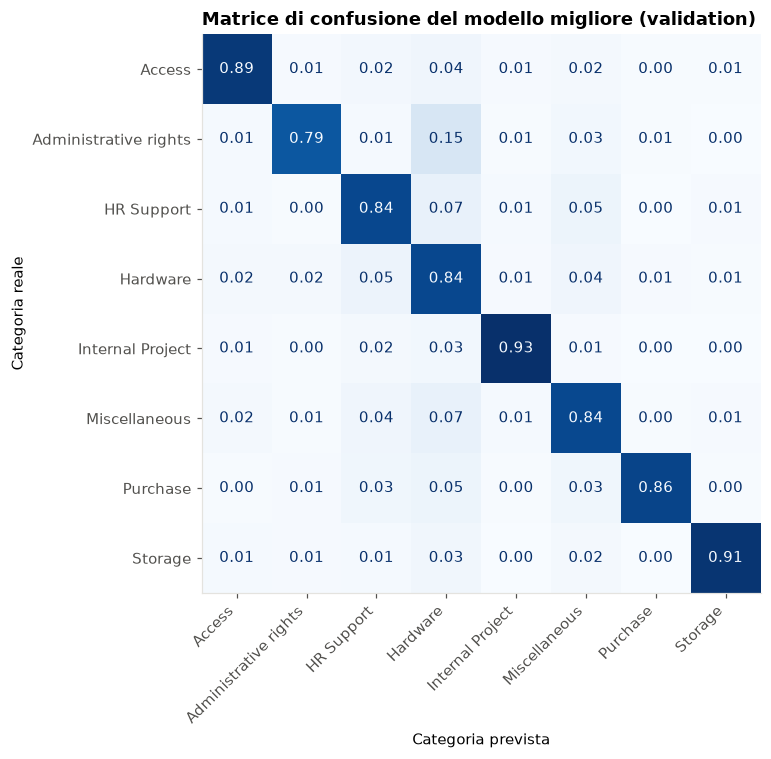

In [14]:
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay.from_predictions(
    y_val, pred_migliore, normalize="true", values_format=".2f", cmap="Blues", xticks_rotation=45, colorbar=False, ax=ax,
)
ax.set_title("Matrice di confusione del modello migliore (validation)")
ax.set_xlabel("Categoria prevista")
ax.set_ylabel("Categoria reale")
ax.grid(False)
plt.setp(ax.get_xticklabels(), ha="right")
plt.tight_layout()
plt.show()

### Verifichiamo i due errori del notebook 02
Controlliamo i due ticket che baseline sbagliava con sicurezza alta e verifichiamo se i bigrammi sono stati utili

In [15]:
casi = val[val[TEXT_COL].str.contains("time card approval|installation the memories", regex=True)]
if len(casi) == 0:
    print("I due ticket non sono nella tua validation")
else:
    risultato_casi = casi[[TEXT_COL, LABEL_COL]].copy()
    risultato_casi[TEXT_COL] = risultato_casi[TEXT_COL].str.slice(0, 80)
    risultato_casi["baseline"] = baseline.predict(casi[TEXT_COL])
    risultato_casi["migliore"] = modello_migliore.predict(casi[TEXT_COL])
    display(risultato_casi)

,Document,Topic_group,baseline,migliore
13064,installation the memories friday pm upgrade has assigned hi got part memories ar,Hardware,Administrative rights,Miscellaneous
14791,time card approval tuesday pm card issue importance high hi seems issues present,HR Support,Access,Access


## Osservazioni (parte 7)

- Validation: F1 macro 0,8453 -> 0,8553 (+0,0100), accuratezza 0,845 -> 0,858.
  Il miglioramento è coerente con la cross-validation (+0,0119): le scelte generalizzano su dati mai visti.
- **7 categorie su 8 migliorano** (HR Support +0,020, Hardware e Administrative rights +0,017, Internal Project +0,014,
  Storage +0,013). Purchase −0,008, pari a 1-2 ticket su 202: variazione casuale.
- Administrative rights più equilibrata: precision 0,654 -> 0,735, recall 0,869 -> 0,790, F1 0,745 -> 0,762.
  Meno falsi positivi da Hardware (4% -> 2%), ma più ticket finiscono in Hardware (10% -> 15%): Hardware resta la "calamita".
- Precision macro 0,826 -> 0,848 con recall stabile (0,866 -> 0,864).
- I due ticket del notebook 02 restano sbagliati ("installation the memories" -> Miscellaneous, "time card approval" -> Access):
  l'ipotesi sui bigrammi non è confermata per questi casi specifici. Probabile causa: bigrammi troppo rari, eliminati da min_df=5.

# 8. Probabilità per l'app
Nel notebook 02 abbiamo deciso che l'app userà la sicurezza del modello: sotto una soglia il chatbot chiederà più dettagli. Per farlo il modello deve fornire una probabilità con `predict_proba`. Regressione logistica e Naive Bayes la forniscono direttamente mentre la SVM lineare no.

Essendo SVM il modello migliore la avvolgiamo in `CalibratedClassifierCV` così che il calibratore addestri la SVM su parti del train ed impari a trasformare le distanze in probabilità

In [16]:
%%time
modello_finale = Pipeline([
    ("tfidf", clone(modello_migliore.named_steps["tfidf"])),
    ("classificatore", CalibratedClassifierCV(clone(modello_migliore.named_steps["classificatore"]), method="sigmoid", cv=5))
])
modello_finale.fit(X_train, y_train)
pred_finale = modello_finale.predict(X_val)
sicurezza = modello_finale.predict_proba(X_val).max(axis=1)
corretto = pred_finale == y_val.to_numpy()

print(f"F1 macro (validation): {f1_score(y_val, pred_finale, average="macro"):.4f}")
print(f"Sicurezza media quando ha ragione: {sicurezza[corretto].mean():.2f}")
print(f"Sicurezza media quando sbaglia: {sicurezza[~corretto].mean():.2f}")

F1 macro (validation): 0.8554
Sicurezza media quando ha ragione: 0.83
Sicurezza media quando sbaglia: 0.57
CPU times: total: 4.41 s
Wall time: 4.57 s


## Osservazioni (parte 8)

- F1 macro dopo la calibrazione: **0,8554** (prima 0,8553): le probabilità non costano nulla in prestazioni.
- Sicurezza media: **0,83 quando ha ragione, 0,57 quando sbaglia** (baseline: 0,80 / 0,50).
  Il segnale resta utile, ma il distacco è minore: gli errori rimasti sono più spesso casi difficili,
  e la calibrazione, non fatta per gruppi, può essere un po' troppo sicura.
  -> La soglia per chiedere dettagli dovrà essere più alta: la sceglierò sul modello finale.

# 9. Salvataggio
Salviamo il modello finale (con le probabilità) e la tabella di tutti i risultati della cross-validation. Ci serviranno per il confronto con la rete LSTM

In [17]:
joblib.dump(modello_finale, MODELS_DIR / "modello_classico_migliore.joblib")

riepilogo_cv = pd.concat([
    tabella_cv,
    pd.DataFrame([{
    "configurazione": f"{CONFIGURAZIONE_SCELTA} ottimizzato",
    "F1 macro (media)": round(ricerca.best_score_, 4),
    "deviazione standard": round(ricerca.cv_results_["std_test_score"][ricerca.best_index_], 4),
    }]).set_index("configurazione"),
])
riepilogo_cv.to_csv(MODELS_DIR / "risultati_modelli_classici.csv")

with open(MODELS_DIR / "parametri_modello_classico.json", "w", encoding="utf-8") as f:
    json.dump({"configurazione": CONFIGURAZIONE_SCELTA,
               "parametri": {k: v for k, v in ricerca.best_params_.items()}}, f, indent=2)

print("Salvati in: ", MODELS_DIR.resolve())

Salvati in:  C:\Users\logic\Desktop\PROGRAMMAZIONE\GitHub\Capstone_Project\models


# 10. Riepilogo
| Aspetto | Valore / osservazione |
|---|---|
| Baseline in cross-validation (media ± dev. std) | **0,8447 ± 0,0075** (validation: 0,8453) |
| Migliore algoritmo con parole singole | Regressione logistica (0,8447) e SVM lineare (0,8445) equivalenti; Naive Bayes 0,7745, k-NN 0,7472 |
| Effetto dei bigrammi | Migliorano tutti: SVM +0,0076, regressione logistica +0,0049, Naive Bayes +0,0251 |
| Configurazione scelta | **SVM lineare con bigrammi** (più alta, più stabile e più veloce della regressione logistica equivalente) |
| Parametri migliori | C = 0,3; class_weight = "balanced"; sublinear_tf = True (decisivo solo C) |
| F1 macro in cross-validation (ottimizzato) | **0,8566 ± 0,0043** |
| F1 macro sulla validation: baseline -> migliore | **0,8453 -> 0,8553** (+0,0100, coerente con la cross-validation) |
| Categorie che migliorano / peggiorano | 7 su 8 migliorano (HR +0,020, Hardware e Administrative rights +0,017); Purchase −0,008 (1-2 ticket, rumore). Administrative rights più equilibrata (precision 0,654 -> 0,735) |
| Ticket *time card* e *memories* | Ancora sbagliati (-> Access, -> Miscellaneous): bigrammi probabilmente troppo rari per min_df=5 |
| Calibrazione e sicurezza media (corretti vs errati) | Calibrazione sigmoid: F1 invariato (0,8554); sicurezza 0,83 vs 0,57 |